# GPT-2 small activation atlas: exploring stage 1

Reads the outputs of `python -m atlas` (see `docs/atlas-design.md`) and looks at what they say about GPT-2 small.
Build them first with `run-atlas` (and, for §5, `run-atlas results/atlas-fineweb 1e6 fineweb` and
`run-atlas results/atlas-code 1e6 code`; for §6, the deep scan in `docs/results.md`): 1M tokens, one 127-token window from each of ~8k documents across two OpenWebText
files, run as 8 shards for bootstrap errors; about 5 minutes on an M4.

1. Residual-stream geometry: how variance and effective dimension grow with depth
2. MLP neurons: firing rates and peak activations by layer
3. Single units: a neuron's histogram and top contexts; a residual dimension's top and bottom contexts
4. Statistical errors (bootstrap over shards) and a within-corpus check (file vs file)
5. Corpus systematic: OpenWebText vs FineWeb vs Python code
6. Deep scan of layers 0–2: rare and never-firing neurons over 50M tokens
7. Regression check: stored exemplar pointers reproduce on recompute

Figures are saved to `docs/figures/` for `docs/results.md`; run headless with `run-notebook`.

All statistics exclude position 0 (BOS) and are conditional on OpenWebText and positions 1–127.

In [1]:
import json
from pathlib import Path
from types import SimpleNamespace

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import torch
import pandas as pd
from atlas import HFGPT2, bootstrap_weights, pooled_moments

ATLAS = Path("../results/atlas")
FIGURES = Path("../docs/figures")  # figures for docs/results.md
manifest = json.loads((ATLAS / "manifest.json").read_text())
neurons = duckdb.sql(f"select * from '{ATLAS / 'neurons.parquet'}'").df()
topk = duckdb.sql(f"select * from '{ATLAS / 'topk.parquet'}'").df()
resid = np.load(ATLAS / "resid.npz")
hists = np.load(ATLAS / "histograms.npz")
tokens = np.load(ATLAS / "tokens.npy", mmap_mode="r")

# Categorical slots 1-4 and text inks of the dataviz default palette, as in the ioi-hydra notebook.
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

def tidy(ax):
    ax.grid(axis="y", color=GRID, zorder=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

print(f"{manifest['n_rows']:,} rows x {manifest['seq_len']} tokens from {manifest['n_docs']:,} documents "
      f"({manifest['dataset']} files {manifest['files']}, at most {manifest['max_windows_per_doc']} window per document)")
print(f"{neurons['n'].iloc[0]:,} tokens per unit; {len(neurons):,} units; {len(topk):,} top- and bottom-k exemplars")

7,814 rows x 128 tokens from 7,814 documents (owt files [0, 1], at most 1 window per document)
992,378 tokens per unit; 46,848 units; 1,136,640 top- and bottom-k exemplars


## 1. Residual-stream geometry

From the per-layer covariance in `resid.npz` ("layer 12" is the final residual stream, the input to `ln_final`).

- **Total variance**, the trace of the covariance: how much the stream's spread grows with depth.
- **Effective dimension**, the participation ratio $(\sum_i \lambda_i)^2 / \sum_i \lambda_i^2$ of the eigenvalues: about
  1 if one direction carries everything, 768 if variance is spread evenly.
- **Largest single basis dimension's share of variance**: the residual basis is not privileged in general, but GPT-2 is
  known to have a few outlier dimensions (447 among them).

*Expect:* variance growing roughly exponentially with depth, and a low effective dimension where outlier dimensions dominate.

layer  total var        eff. dim      dims for 90%  top basis dim (share)
    0      11.6 ± 0.0     14.3 ± 0.0            411   479 (2%)
    1    1033.0 ± 0.7     31.1 ± 0.0            314   480 (7%)
    2    1321.7 ± 0.9     46.2 ± 0.0            327   480 (7%)
    3    1662.3 ± 0.9     71.7 ± 0.1            378   480 (5%)
    4    2155.9 ± 1.1    103.9 ± 0.1            424   480 (4%)
    5    2667.8 ± 1.2    131.3 ± 0.1            449   480 (3%)
    6    3380.5 ± 1.4    150.5 ± 0.2            468   480 (3%)
    7    4343.2 ± 1.5    164.4 ± 0.3            485   480 (2%)
    8    5865.7 ± 2.1    169.8 ± 0.3            500   447 (2%)
    9    8113.7 ± 2.4    170.8 ± 0.2            507   447 (2%)
   10   11950.5 ± 4.7    156.6 ± 0.2            515   481 (2%)
   11   19089.0 ± 11.7   103.0 ± 0.3            510   496 (2%)
   12   56610.9 ± 164.7    6.7 ± 0.0            345   496 (10%)


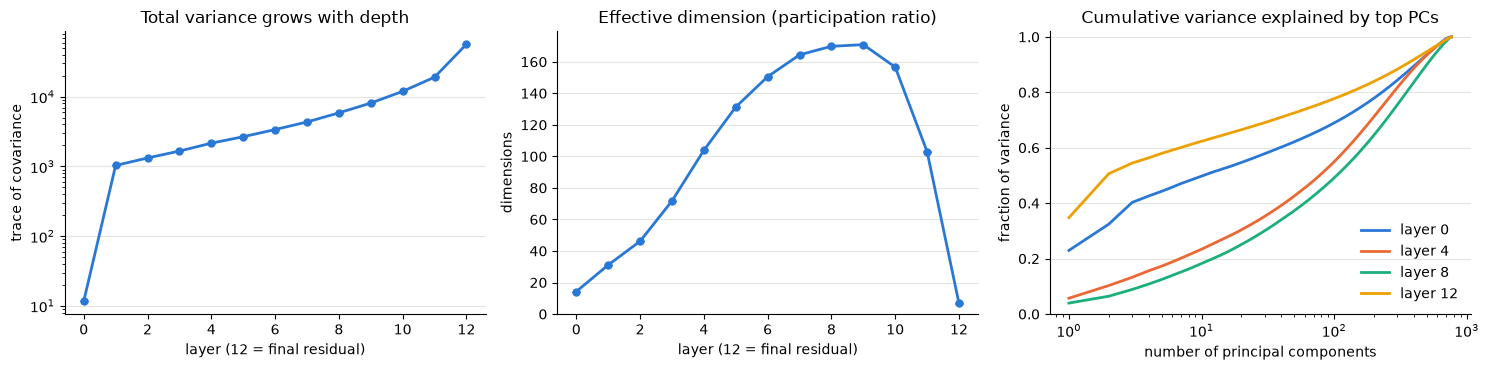

In [2]:
layers, cov = resid["layer"], resid["cov"]
eig = np.linalg.eigvalsh(cov)[:, ::-1]  # [13, 768], descending
total, pr = resid["total_var"], resid["pr"]  # = eig.sum(1) and eig.sum(1)**2 / (eig**2).sum(1)
total_err, pr_err = resid["total_var_err"], resid["pr_err"]  # bootstrap over shards
diag = np.diagonal(cov, axis1=1, axis2=2)
top_dim, top_share = diag.argmax(1), diag.max(1) / total
dims90 = (np.cumsum(eig, 1) / total[:, None] < 0.9).sum(1) + 1

print("layer  total var        eff. dim      dims for 90%  top basis dim (share)")
for l in layers:
    print(f"{l:5d}  {total[l]:8.1f} ± {total_err[l]:<5.1f}  {pr[l]:5.1f} ± {pr_err[l]:<4.1f}  {dims90[l]:12d}  {top_dim[l]:4d} ({top_share[l]:.0%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].errorbar(layers, total, yerr=total_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[0].set(yscale="log", title="Total variance grows with depth", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].errorbar(layers, pr, yerr=pr_err, fmt="o-", color=C[0], lw=2, ms=5, capsize=3)
axes[1].set(title="Effective dimension (participation ratio)", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
for i, l in enumerate([0, 4, 8, 12]):
    axes[2].plot(np.arange(1, 769), np.cumsum(eig[l]) / total[l], color=C[i], lw=2, label=f"layer {l}")
axes[2].set(xscale="log", title="Cumulative variance explained by top PCs", xlabel="number of principal components", ylabel="fraction of variance", ylim=(0, 1.02))
axes[2].legend(frameon=False, loc="lower right")
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_resid_geometry")

**Reading it.** The first block multiplies the stream's variance by about 90 (layer 0 is the embedding alone), and it
grows steadily after that, another 3× in the last block. The effective dimension rises from 14 to about 170 by layers
7–9, then collapses to about 7 at the final residual stream, where a handful of directions carry most of the variance
(the top principal component alone carries about a third). In the basis, dimension 480 stands out early (7.5% of the
variance at layer 1, falling to 2% by layer 7); from layer 7 to 11 no dimension carries more than about 2.5%, so which
one is largest there is not meaningful. At the final residual, dimensions 496, 430 and 36 carry 11%, 8% and 8%. The
bootstrap errors are tiny: the effective dimension is known to better than ±0.5 at every layer.

## 2. MLP neurons

Each neuron's firing rate (fraction of tokens with post-GELU activation > 0) and its peak activation, summarized per
layer as the median with a 10th–90th percentile band. Rarely-firing neurons are those with a firing rate below 1e-4,
fewer than about 100 tokens in 1M.

*Expect:* early layers to hold most of the rarely-firing neurons, and peak activations to grow in the last layers.

highest-peak neurons:
 layer  unit       max     mean      std  frac_pos      p999
    11  2378 59.611004 1.029139 5.445017  0.059583 47.936045
    10  2931 22.611681 0.282076 1.501786  0.066540 15.890984
    10  2114 20.808746 0.227342 1.814021  0.025399 17.100327
    11  2679 17.533356 0.440449 1.809477  0.100282 14.523485
    11   584 17.443029 0.414914 1.968647  0.063556 14.957618


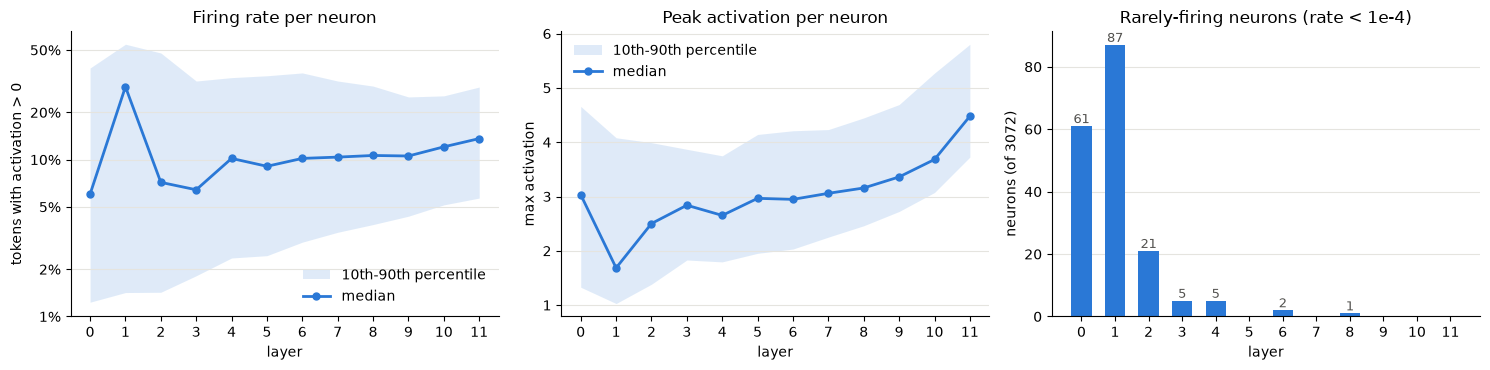

In [3]:
mlp = neurons[neurons.kind == "post"]
by = mlp.groupby("layer")
q = lambda col, p: by[col].quantile(p).to_numpy()
L = np.arange(12)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title, ylabel, log in [
    (axes[0], "frac_pos", "Firing rate per neuron", "tokens with activation > 0", True),
    (axes[1], "max", "Peak activation per neuron", "max activation", False),
]:
    ax.fill_between(L, q(col, 0.1), q(col, 0.9), color=C[0], alpha=0.15, lw=0, label="10th-90th percentile")
    ax.plot(L, q(col, 0.5), "o-", color=C[0], lw=2, ms=5, label="median")
    ax.set(title=title, xlabel="layer", ylabel=ylabel, yscale="log" if log else "linear")
    if log:
        ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5], ["1%", "2%", "5%", "10%", "20%", "50%"])
        ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.legend(frameon=False)
rare = by["frac_pos"].apply(lambda s: (s < 1e-4).sum()).to_numpy()
axes[2].bar(L, rare, color=C[0], width=0.6, zorder=2)
for l, n in zip(L, rare):
    if n:
        axes[2].text(l, n, str(n), ha="center", va="bottom", fontsize=9, color=INK2)
axes[2].set(title="Rarely-firing neurons (rate < 1e-4)", xlabel="layer", ylabel="neurons (of 3072)")
for ax in axes:
    ax.set_xticks(L)
    tidy(ax)
plt.tight_layout()
save(fig, "results_mlp_neurons")

print("highest-peak neurons:")
print(mlp.nlargest(5, "max")[["layer", "unit", "max", "mean", "std", "frac_pos", "p999"]].to_string(index=False))

**Reading it.** Layers 0–2 hold most of the rarely-firing neurons (61, 87 and 21 of 3072). Layer 1 is the odd one out:
its median neuron fires on about 30% of tokens, more than twice the median of any other layer. Peak activations climb steadily
through the last layers, and the highest-peak neurons are all in layers 10–11.

## 3. Single units

`show_neuron(layer, unit)` prints the neuron's summary row, plots its activation histogram (from `histograms.npz`, on
an asinh axis: linear near 0, logarithmic in the tails) and lists its top-activating contexts with the token marked «like this». For a residual dimension
(`hook="blocks.L.hook_resid_pre"`), which is signed, it also lists the bottom (most negative) contexts.

blocks.9.mlp.hook_post unit 1000: mean -0.082, std 0.145, max 2.85, fires on 7.9% of tokens, p50 -0.117, p99 0.62, p99.9 1.39


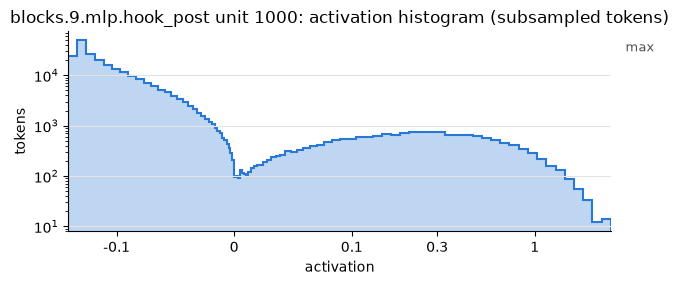

top contexts:
     2.85  , read or possess religious books or material of« my» choosing.⏎⏎
     2.83  senal without a single representative.⏎⏎Harry Kane is one of« a» number of English players
     2.80  years in the making is about to culminate with the launch of a one-of-a«-»kind satellite.⏎
     2.78  tude “except as a punishment for crime whereof the party shall« have» been duly convicted.
     2.72  the crash scene to the Foothills Medical Centre. The driver, a woman in« her» mid thirties
     2.70   endorse the instruments of her« own» oppression? Could it
     2.70  ials did not respond to requests for comment.⏎⏎The case has« only» become public recently,
     2.53   would authorise and fully endorse a vote in a manner, and at a time, of« our» choosing.⏎⏎
     2.53  potentially life threatening condition while the passenger, a woman in her« early» fifties
     2.51  . Ald. Bob Fioretti, 2«nd», offers a poorly


In [4]:
EDGES = hists["edges"]

def show_neuron(layer, unit, n=10, hook=None, save_as=None):
    hook = hook or f"blocks.{layer}.mlp.hook_post"
    row = neurons[(neurons.hook == hook) & (neurons.unit == unit)].iloc[0]
    print(f"{hook} unit {unit}: mean {row['mean']:.3f}, std {row['std']:.3f}, max {row['max']:.2f}, "
          f"fires on {row.frac_pos:.1%} of tokens, p50 {row.p50:.3f}, p99 {row.p99:.2f}, p99.9 {row.p999:.2f}")
    counts = hists[hook][unit]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5, fill=True, alpha=0.3)
    ax.stairs(counts[1:-1], EDGES, color=C[0], lw=1.5)
    ax.axvline(row["max"], color=INK2, lw=1, ls="--")
    ax.annotate("max", (row["max"], 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
    nz = np.nonzero(counts[1:-1])[0]
    lo, hi = EDGES[nz[0]], EDGES[nz[-1] + 1]
    ax.set_xscale("asinh", linear_width=0.05)
    ticks = [t for t in (-1, -0.1, 0, 0.1, 0.3, 1, 3, 10, 30, 100) if lo <= t <= hi]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
    ax.set(yscale="log", xlim=(lo, hi),
           title=f"{hook} unit {unit}: activation histogram (subsampled tokens)", xlabel="activation", ylabel="tokens")
    tidy(ax)
    if save_as:
        save(fig, save_as)
    plt.show()
    for side in ("top", "bottom"):
        t = topk[(topk.hook == hook) & (topk.unit == unit) & (topk.side == side)].sort_values("rank").head(n)
        if len(t):
            print(f"{side} contexts:")
        for v, ctx in zip(t.value, t.context):
            print(f"  {v:7.2f}  {ctx[-90:]}")

show_neuron(9, 1000, save_as="results_neuron_l9_1000")

blocks.11.mlp.hook_post unit 2378: mean 1.029, std 5.445, max 59.61, fires on 6.0% of tokens, p50 -0.001, p99 37.45, p99.9 47.94


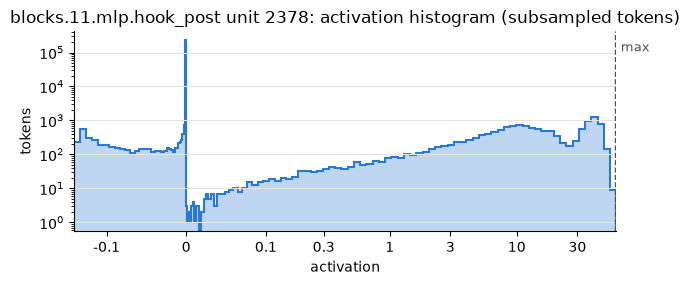

top contexts:
    59.61  the powerful impact that such announcements can have on clinician behaviour.«⏎»⏎"Until now
    58.87  incing evidence that such changes in practice have affected suicidal behaviour.«⏎»⏎"The US
    57.86  be better next time. Any communication can have intended and unintended consequences.«⏎»⏎"
    57.28  Hawaii: Neil Abercrombie⏎⏎Kentucky: Ed Whitfield«⏎»⏎Maryland:
    56.51   income earners.⏎⏎"Conclusively said that they'll be cutting the pension.«⏎»⏎"Conclusively
    55.94  n a unified way and we have an issue there because of departmental government.«⏎»⏎"What we
    55.90  ry families.⏎⏎"It was a remarkable result and the lesson I take from it is clear.«⏎»⏎"It's
    55.77   it.⏎⏎"But there's only been four races, and we know that things can change.«⏎»⏎"Actually,
    55.72  ) later on, had a few drinks and this topic came up and I was talking about it.«⏎»⏎"It got
    55.52  ram.⏎⏎• Staff a thrift shop in Friendswood that supports services to the needy.«⏎»⏎• B

In [5]:
# The neuron with the largest peak activation in the last layer.
l11 = mlp[mlp.layer == 11].nlargest(1, "max").iloc[0]
show_neuron(11, int(l11.unit), save_as="results_neuron_l11_peak")

**A residual dimension.** Residual dimensions are signed, so the atlas keeps both extremes. Dimension 447 is the
basis dimension with the largest share of variance in layers 8–10 (§1); here it is at the input to layer 9.

blocks.9.hook_resid_pre unit 447: mean 49.262, std 12.093, max 101.55, fires on 99.9% of tokens, p50 50.218, p99 75.53, p99.9 84.57


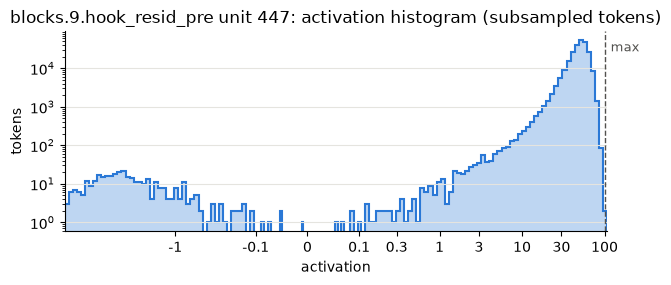

top contexts:
   101.55   was prosecuted and ultimately convicted.⏎⏎The FBI stated that« Polic»arpio became enraged
    98.89  : Revising — not eliminating — tests to make Va. schools better]⏎⏎«Hol»ton is also leading
    97.89  first person to identify what it was that I fixed wins a free copy of« Idle» Feet! You may
    97.48   did not have any official policies or procedures for the use of« Theft»Track. Neither its
    97.22  protocols is the user unwareness of their weaknesses. Although« Chat»Secure's Facebook and
    96.80  heir iPhone or iPad in order to install it.⏎⏎For those unfamiliar with« Pop»corn Time, the
    96.28  ?⏎⏎The« flashlight» runs 30mins continuously
    95.78  power consumption, providing value and excitement for years to come.⏎⏎About« Dak»tronics⏎⏎
    95.74  me too soon.⏎⏎One of the terrorists shot down into the alley, and« Ps»enny caught a bullet
    95.73  What if« Spotify» made a Podcast App
bottom contexts:
   -29.96  ry 2017 January 2017 December 2016 Nov

In [6]:
show_neuron(9, 447, hook="blocks.9.hook_resid_pre", save_as="results_resid_l9_447")

## 4. Statistical errors and a within-corpus check

`export` resamples the 8 shards with replacement (within each OpenWebText file) and pools them, giving a bootstrap
error on every unit's mean, std and firing rate (`*_err` columns), and on each layer's total variance and effective
dimension (§1). Whole shards are the resampling unit, so correlations between rows within a shard are accounted for.

**Within-corpus check: file 0 vs file 1.** With only 4 shards per file, each unit's error estimate is itself too noisy
for per-unit z-tests (z then follows a heavy-tailed distribution even when nothing differs). A robust test avoids
per-unit errors: compare the typical cross-file difference with the typical difference between two halves of the same
file, each in units of the unit's spread. Halves hold half the data, so their differences are divided by √2 to be
comparable. A ratio near 1 means the files differ no more than random splits do.

median bootstrap error             MLP neurons   residual dims
  on the mean, in units of std         0.0017         0.0019
  on the std, relative                 0.0044         0.0010
  on the firing rate, relative         0.0053         0.0017



|difference| / spread       cross-file   halves (÷√2)   ratio, median   ratio, 99th pct
Mean activat MLP neurons       0.0032       0.0028           1.12             1.12
Mean activat residual dims     0.0036       0.0032           1.14             1.12
Firing rate  MLP neurons       0.0033       0.0029           1.13             1.10



effective dimension by file (± bootstrap within the file)
layer  file 0           file 1           both files
    0   14.3 ± 0.0      14.3 ± 0.0      14.3 ± 0.0
    1   31.1 ± 0.0      31.1 ± 0.0      31.1 ± 0.0
    2   46.2 ± 0.1      46.1 ± 0.1      46.2 ± 0.0
    3   71.7 ± 0.1      71.8 ± 0.1      71.7 ± 0.1
    4  103.6 ± 0.2     104.0 ± 0.1     103.9 ± 0.1
    5  131.0 ± 0.2     131.5 ± 0.2     131.3 ± 0.1
    6  150.2 ± 0.3     150.8 ± 0.2     150.5 ± 0.2
    7  164.1 ± 0.4     164.5 ± 0.4     164.4 ± 0.3
    8  169.8 ± 0.3     169.6 ± 0.5     169.8 ± 0.3
    9  171.0 ± 0.2     170.5 ± 0.4     170.8 ± 0.2
   10  156.6 ± 0.3     156.4 ± 0.3     156.6 ± 0.2
   11  102.9 ± 0.5     102.9 ± 0.4     103.0 ± 0.3
   12    6.8 ± 0.0       6.7 ± 0.1       6.7 ± 0.0


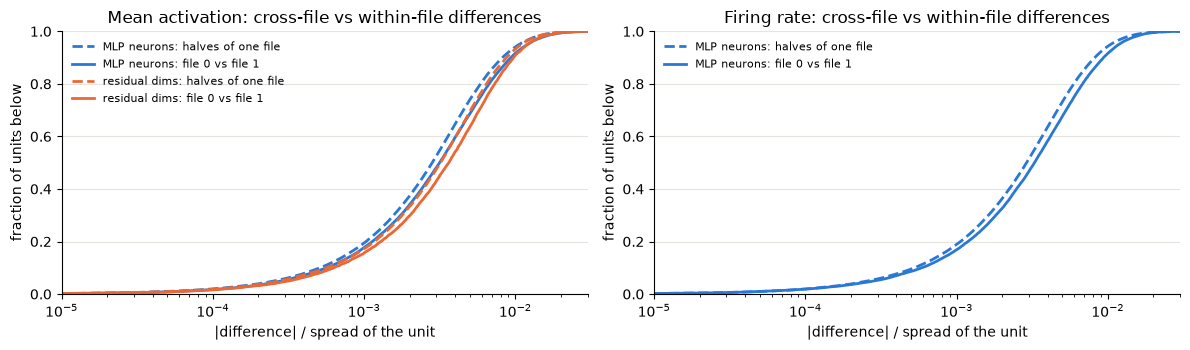

In [7]:
mlp_mask = (neurons.kind == "post").to_numpy()
print("median bootstrap error             MLP neurons   residual dims")
for label, ratio in [("on the mean, in units of std", neurons.mean_err / neurons["std"]),
                     ("on the std, relative", neurons.std_err / neurons["std"]),
                     ("on the firing rate, relative", neurons.frac_pos_err / neurons.frac_pos.where(neurons.frac_pos > 0))]:
    print(f"  {label:32s} {np.nanmedian(ratio[mlp_mask]):10.4f}   {np.nanmedian(ratio[~mlp_mask]):12.4f}")

# Per-shard moments, in the same unit order as `neurons`.
sh = pd.read_parquet(ATLAS / "shards.parquet")
S, U = sh.shard.nunique(), len(neurons)
assert (sh.hook.to_numpy()[:U] == neurons.hook.to_numpy()).all() and (sh.unit.to_numpy()[:U] == neurons.unit.to_numpy()).all()
arr = lambda col: sh[col].to_numpy().reshape(S, U)
n_s, files_s = arr("n")[:, 0], arr("file")[:, 0]
moments_s = (n_s, arr("mean"), arr("m2"), arr("n_pos"))
pool = lambda mask: pooled_moments(np.asarray(mask, float)[None], *moments_s)

f0, f1 = np.unique(files_s)
spread = {"mean": neurons["std"].to_numpy(), "frac_pos": np.sqrt(neurons.frac_pos * (1 - neurons.frac_pos)).to_numpy()}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
print("\n|difference| / spread       cross-file   halves (÷√2)   ratio, median   ratio, 99th pct")
for ax, (col, title) in zip(axes, [("mean", "Mean activation"), ("frac_pos", "Firing rate")]):
    with np.errstate(divide="ignore", invalid="ignore"):
        cross = np.abs(pool(files_s == f0)[col][0] - pool(files_s == f1)[col][0]) / spread[col]
        halves = []
        for f in (f0, f1):
            idx = np.flatnonzero(files_s == f)
            for pair in ([0, 1], [0, 2], [0, 3]):  # the three ways to split 4 shards into two halves
                h = np.zeros(S); h[idx[pair]] = 1
                halves.append(np.abs(pool(h)[col][0] - pool((files_s == f) - h)[col][0]) / spread[col] / np.sqrt(2))
    for i, (m, label) in enumerate([(mlp_mask, "MLP neurons"), (~mlp_mask, "residual dims")]):
        if col == "frac_pos" and label == "residual dims":
            continue  # "> 0" is not meaningful for residual dimensions
        c = cross[m & np.isfinite(cross)]
        h = np.concatenate([x[m & np.isfinite(x)] for x in halves])
        print(f"{title[:12]:12s} {label:13s} {np.median(c):10.4f}   {np.median(h):10.4f}   {np.median(c) / np.median(h):12.2f}   "
              f"{np.quantile(c, 0.99) / np.quantile(h, 0.99):14.2f}")
        for vals, ls, which in [(h, "--", "halves of one file"), (c, "-", f"file {f0} vs file {f1}")]:
            v = np.sort(vals)
            ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=C[i], lw=2, ls=ls, label=f"{label}: {which}")
    ax.set(xscale="log", xlim=(1e-5, 3e-2), ylim=(0, 1), title=f"{title}: cross-file vs within-file differences",
           xlabel="|difference| / spread of the unit", ylabel="fraction of units below")
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_corpus_check")

print("\neffective dimension by file (± bootstrap within the file)")
print("layer  " + "  ".join(f"file {f:<10}" for f in resid["files"]) + "  both files")
for l in layers:
    cells = "  ".join(f"{resid['pr_file'][l, j]:5.1f} ± {resid['pr_err_file'][l, j]:<4.1f}  " for j in range(len(resid["files"])))
    print(f"{l:5d}  {cells}  {pr[l]:5.1f} ± {pr_err[l]:.1f}")

**Reading it.** Statistical errors are small: a neuron's mean is known to about 0.002 of its spread, which corresponds
to roughly 250k effective samples out of 1M tokens (tokens within documents and shards are correlated). The two
OpenWebText files differ slightly *more* than two halves of one file: the ratio is about 1.1 in the median and the tail,
and a per-unit z-test on shard means finds excess variance (z variance 1.8 against 1.4 for a split mixing the files).
The files hold different documents (none shared), and the difference is small (about 0.0015 of a unit's spread), but
it is real, so the bootstrap over shards within a file understates the error from one file of the corpus to the next.
Their effective dimensions agree within about 0.5. §5 compares genuinely different corpora.

## 5. Corpus systematic: OpenWebText vs FineWeb vs Python code

Every number above is conditional on OpenWebText. The same pipeline, sampling and 1M-token budget run on two more
corpora: **FineWeb** (sample-10BT; filtered Common Crawl, web text like OpenWebText but a different selection) and
**Python code** (codeparrot-clean, from GitHub), a deliberately different distribution.

**Per-unit shift.** For each unit, |mean on corpus X − mean on OpenWebText| in units of the unit's spread on
OpenWebText, compared with a *within-corpus floor*: the same quantity between OpenWebText's two files, scaled by 1/√2
because each file holds half the data (statistical noise plus the small file-to-file difference of §4). A curve to the
right of the floor is a corpus dependence beyond that. Firing rates are
compared as |log₁₀ ratio|.

*Expect:* FineWeb close to OpenWebText but above the floor; code far from both.

OpenWebText    Skylion007/openwebtext ['plain_text/train-00000-of-00080.parquet', 'plain_text/train-00001-of-00080.parquet']
FineWeb        HuggingFaceFW/fineweb ['sample/10BT/000_00000.parquet', 'sample/10BT/001_00000.parquet']
code (Python)  codeparrot/codeparrot-clean ['default/partial-train/0000.parquet', 'default/partial-train/0001.parquet']

median shift (× within-OWT floor)                FineWeb         code (Python)   floor
  MLP neurons: mean shift               0.028 (   12×)       0.172 (   77×)       0.0022
  Residual dims: mean shift             0.037 (   14×)       0.263 (  102×)       0.0026
  MLP neurons: firing-rate shift        0.044 (   15×)       0.335 (  117×)       0.0029


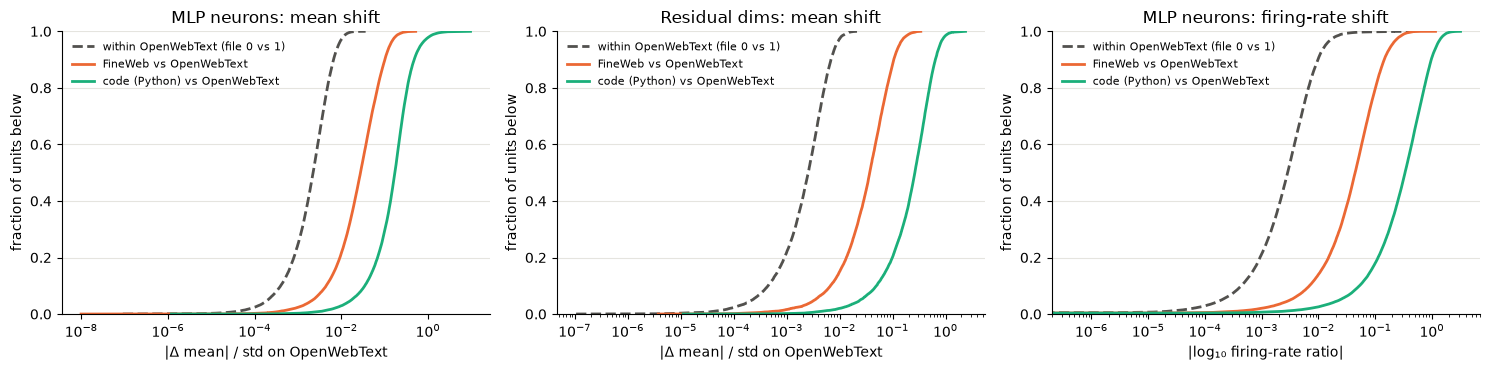

In [8]:
CORPORA = {"OpenWebText": ATLAS, "FineWeb": Path("../results/atlas-fineweb"), "code (Python)": Path("../results/atlas-code")}
corp = {}
for name, path in CORPORA.items():
    n_ = duckdb.sql(f"select * from '{path / 'neurons.parquet'}'").df()
    assert (n_.hook.to_numpy() == neurons.hook.to_numpy()).all() and (n_.unit.to_numpy() == neurons.unit.to_numpy()).all()
    corp[name] = SimpleNamespace(neurons=n_, resid=np.load(path / "resid.npz"), manifest=json.loads((path / "manifest.json").read_text()))
    print(f"{name:14s} {corp[name].manifest['repo']} {corp[name].manifest['paths']}")

owt = corp["OpenWebText"].neurons
sd = owt["std"].to_numpy()
smooth = lambda frac, n: (frac * n + 1) / (n + 2)  # firing rates with a pseudo-count, so log ratios stay finite
log_fr = lambda nn: np.log10(smooth(nn.frac_pos.to_numpy(), nn.n.to_numpy()))
# Noise floor from OpenWebText's two files (pooled per file from shards.parquet, §4), scaled to full-size samples.
p0, p1 = pool(files_s == f0), pool(files_s == f1)
n_file = n_s[files_s == f0].sum()
floor = {"mean": np.abs(p0["mean"][0] - p1["mean"][0]) / sd / np.sqrt(2),
         "fr": np.abs(np.log10(smooth(p0["frac_pos"][0], n_file)) - np.log10(smooth(p1["frac_pos"][0], n_file))) / np.sqrt(2)}
shift = {name: {"mean": np.abs(c.neurons["mean"].to_numpy() - owt["mean"].to_numpy()) / sd,
                "fr": np.abs(log_fr(c.neurons) - log_fr(owt))} for name, c in corp.items() if name != "OpenWebText"}

panels = [("mean", mlp_mask, "MLP neurons: mean shift", "|Δ mean| / std on OpenWebText"),
          ("mean", ~mlp_mask, "Residual dims: mean shift", "|Δ mean| / std on OpenWebText"),
          ("fr", mlp_mask, "MLP neurons: firing-rate shift", "|log₁₀ firing-rate ratio|")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
print("\nmedian shift (× within-OWT floor) " + "".join(f"{n:>22s}" for n in shift) + "   floor")
for ax, (key, m, title, xlabel) in zip(axes, panels):
    for vals, color, ls, label in [(floor[key], INK2, "--", "within OpenWebText (file 0 vs 1)")] + \
            [(shift[n][key], C[i + 1], "-", f"{n} vs OpenWebText") for i, n in enumerate(shift)]:
        v = np.sort(vals[m & np.isfinite(vals)])
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=color, ls=ls, lw=2, label=label)
    ax.set(xscale="log", ylim=(0, 1), title=title, xlabel=xlabel, ylabel="fraction of units below")
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
    fl = np.nanmedian(floor[key][m])
    print(f"  {title:31s}" + "".join(f"{np.nanmedian(shift[n][key][m]):12.3f} ({np.nanmedian(shift[n][key][m]) / fl:5.0f}×)" for n in shift) + f"   {fl:10.4f}")
plt.tight_layout()
save(fig, "results_corpus_units")

**Per-layer summaries.** Residual-stream total variance and effective dimension (from each corpus's covariance), and
the median MLP neuron's firing rate, by layer.

layer      OpenWebText eff. dim        FineWeb eff. dim  code (Python) eff. dim
    0               14.3 ± 0.0              14.7 ± 0.0              11.7 ± 0.0 
    1               31.1 ± 0.0              31.4 ± 0.0              14.2 ± 0.1 
    2               46.2 ± 0.0              46.3 ± 0.0              17.5 ± 0.1 
    3               71.7 ± 0.1              72.0 ± 0.1              18.0 ± 0.1 
    4              103.9 ± 0.1             105.7 ± 0.1              19.1 ± 0.1 
    5              131.3 ± 0.1             134.4 ± 0.1              24.2 ± 0.1 
    6              150.5 ± 0.2             156.3 ± 0.2              24.9 ± 0.2 
    7              164.4 ± 0.3             172.8 ± 0.3              26.2 ± 0.2 
    8              169.8 ± 0.3             179.7 ± 0.3              24.7 ± 0.2 
    9              170.8 ± 0.2             183.4 ± 0.3              27.1 ± 0.2 
   10              156.6 ± 0.2             171.0 ± 0.2              28.8 ± 0.2 
   11              103.0 ± 0.3          

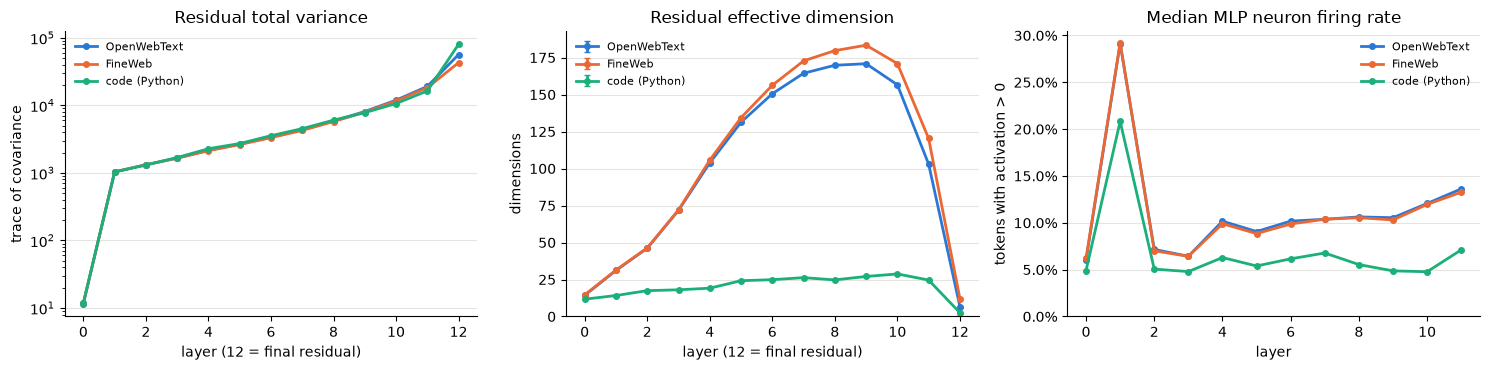

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for i, (name, c) in enumerate(corp.items()):
    r = c.resid
    axes[0].plot(r["layer"], r["total_var"], "o-", color=C[i], lw=2, ms=4, label=name)
    axes[1].errorbar(r["layer"], r["pr"], yerr=r["pr_err"], fmt="o-", color=C[i], lw=2, ms=4, capsize=2, label=name)
    fr = c.neurons[c.neurons.kind == "post"].groupby("layer").frac_pos.median()
    axes[2].plot(fr.index, fr.to_numpy(), "o-", color=C[i], lw=2, ms=4, label=name)
axes[0].set(yscale="log", title="Residual total variance", xlabel="layer (12 = final residual)", ylabel="trace of covariance")
axes[1].set(title="Residual effective dimension", xlabel="layer (12 = final residual)", ylabel="dimensions", ylim=(0, None))
axes[2].set(title="Median MLP neuron firing rate", xlabel="layer", ylabel="tokens with activation > 0", ylim=(0, None))
axes[2].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    tidy(ax)
plt.tight_layout()
save(fig, "results_corpus_layers")

print("layer  " + "".join(f"{n + ' eff. dim':>24s}" for n in corp))
for l in corp["OpenWebText"].resid["layer"]:
    print(f"{l:5d}  " + "".join(f"{c.resid['pr'][l]:17.1f} ± {c.resid['pr_err'][l]:<4.1f}" for c in corp.values()))

**Offset dimensions.** The near-constant residual dimensions found in `docs/results.md` (§2 there): mean ± std
over tokens, per corpus.

In [10]:
OFFSET_DIMS, OFFSET_LAYERS = [64, 266, 326, 373, 447, 481], [1, 6, 11, 12]
res_of = lambda nn: nn[nn.kind == "resid"].set_index(["layer", "unit"])
print("dim  layer  " + "".join(f"{n:>22s}" for n in corp))
for dim in OFFSET_DIMS:
    for l in OFFSET_LAYERS:
        print(f"{dim:3d}  {l:5d}  " + "".join(f"{r.loc[(l, dim), 'mean']:12.1f} ± {r.loc[(l, dim), 'std']:<7.1f}"
                                          for r in map(res_of, (c.neurons for c in corp.values()))))

dim  layer             OpenWebText               FineWeb         code (Python)
 64      1         -23.7 ± 2.0           -23.7 ± 1.9           -23.3 ± 1.9    
 64      6         -27.2 ± 2.2           -27.3 ± 2.2           -28.1 ± 2.3    
 64     11         -28.1 ± 2.2           -28.2 ± 2.2           -28.3 ± 2.2    
 64     12        -118.7 ± 35.4         -124.5 ± 31.0         -108.3 ± 54.8   
266      1          11.3 ± 2.5            11.3 ± 2.5            11.5 ± 2.4    
266      6          11.7 ± 2.4            11.8 ± 2.4            12.8 ± 2.5    
266     11          11.9 ± 2.7            12.0 ± 2.7            13.1 ± 2.8    
266     12        -105.8 ± 39.1         -112.0 ± 35.3          -97.8 ± 60.6   
326      1           9.3 ± 1.7             9.6 ± 1.7            10.6 ± 1.5    
326      6          10.5 ± 2.4            11.2 ± 2.5            13.3 ± 1.9    
326     11          11.6 ± 4.9            13.2 ± 5.1            19.8 ± 5.8    
326     12          12.1 ± 10.1           14.4 ± 10.

373      1         -16.2 ± 4.0           -16.1 ± 4.0           -13.9 ± 4.0    
373      6         -21.3 ± 4.6           -21.5 ± 4.5           -19.8 ± 4.7    
373     11         -93.7 ± 18.0          -94.8 ± 16.0          -88.6 ± 21.9   
373     12        -142.9 ± 39.4         -149.4 ± 32.4         -129.2 ± 62.1   
447      1          17.3 ± 4.4            17.1 ± 4.4            15.0 ± 4.2    
447      6          32.0 ± 8.0            31.9 ± 7.7            30.2 ± 7.8    
447     11          89.3 ± 17.8           89.6 ± 16.0           82.1 ± 22.0   
447     12         127.4 ± 39.1          132.8 ± 34.2          123.0 ± 65.0   
481      1           0.4 ± 1.0             0.4 ± 1.0             0.4 ± 0.9    
481      6           6.4 ± 5.5             6.2 ± 5.3             6.8 ± 4.8    
481     11          92.7 ± 18.9           93.1 ± 17.0           88.5 ± 22.1   
481     12         133.2 ± 39.0          138.6 ± 33.2          124.2 ± 60.8   


**Neurons that change most on code.** The MLP neurons with the largest firing-rate ratio between code and OpenWebText,
each way, with their top context on code.

In [11]:
code_topk = duckdb.sql(f"select * from '{CORPORA['code (Python)'] / 'topk.parquet'}' where kind = 'post' and rank = 0").df().set_index(["layer", "unit"])
cn = corp["code (Python)"].neurons
ratio = log_fr(cn) - log_fr(owt)
frame = owt.assign(fr_owt=owt.frac_pos, fr_code=cn.frac_pos, log_ratio=ratio)[mlp_mask]
for label, rows in [("fire much more on code", frame.nlargest(6, "log_ratio")), ("fire much less on code", frame.nsmallest(4, "log_ratio"))]:
    print(f"{label}:")
    for r in rows.itertuples():
        ctx = code_topk.loc[(r.layer, r.unit), "context"][-70:]
        print(f"  L{r.layer:<2d} {r.unit:4d}  OWT {r.fr_owt:7.2%}  code {r.fr_code:7.2%}  top on code: {ctx!r}")

fire much more on code:
  L0  2469  OWT   0.04%  code  30.10%  top on code: '.⏎⏎« »   If randomly'
  L1  2814  OWT   0.00%  code   0.07%  top on code: '\t\t\t\t\t\t\tpass⏎⏎\t\t\t\t\treturn output⏎⏎«\t»\t\t\tcheck'
  L0  1889  OWT   0.02%  code   9.59%  top on code: '    for s in r:⏎               « i» += 1⏎ '
  L0  2489  OWT   0.00%  code   0.29%  top on code: 'art = True, fnc=boundFunction(main, plugin=x)))⏎⏎«\t»return pluginlist⏎'
  L0  1774  OWT   0.00%  code   0.43%  top on code: '3,4,6,7,8,9]]⏎⏎\tprint("Testing for family: GAMMA")⏎«\t»print'
  L1  1323  OWT   0.06%  code  12.83%  top on code: '       print "\\t\\t\\t\\t\\t\\t\\t\\t\\«t»'
fire much less on code:
  L5  1707  OWT   1.69%  code   0.00%  top on code: " '« +» str( results['"
  L4   961  OWT   9.44%  code   0.01%  top on code: 'ING N«EG»LIGENCE OR'
  L11 2652  OWT   5.22%  code   0.01%  top on code: '== Heaviside(x)⏎    assert conjugate(Heaviside(x - y))« ==» Heaviside('
  L5  1139  OWT   1.65%  code   0.00%  top on code

**Reading it.** FineWeb moves a typical unit 12–15× further than OpenWebText's two files differ from each other; code
moves it 77–117× further. The per-layer picture explains where. FineWeb follows OpenWebText closely but keeps a higher
effective dimension from layer 7 on (183 against 171 at layer 9, 12 against 7 at the final residual). Code differs
from the first block: its effective dimension stays near 25 at every layer, its neurons fire less (median 5–7% after
layer 1, 21% in layer 1), and its total variance at the final residual is 42% higher (FineWeb's is 24% lower). A likely cause is code's token
statistics: 37% of its tokens are pure whitespace (indentation) against 2–4% for web text, and its ten most common
token types cover half of all tokens, so a few directions carry much of the variance. The same residual dimensions are
offsets on all three corpora, with similar means through layer 11 (FineWeb within 4% of OpenWebText, code within
4–17%, except dimension 326, up to 14% and 70% larger), and the rarely-firing neurons are mostly the same neurons (168 rare on every corpus; 109 never fire on any of the 3M tokens), so both look like
properties of the model rather than of the data. A few early neurons are code-specific, nearly silent on web text
and firing on indentation and tabs.

## 6. Deep scan of layers 0–2: rare and never-firing neurons

The atlases above see 1M tokens per corpus, too few to tell a neuron that fires once in 10⁷ tokens from one that never
fires. The deep scan runs only layers 0–2, where almost all the rarely-firing neurons are (§2), over 50M OpenWebText
tokens: 390k documents from files 0–7, one window each, 50× the atlas. The forward pass stops after layer 2.

It records the MLP **pre**-activation (`mlp.hook_pre`), not the post-GELU value. GELU keeps the sign, so the firing
rate (fraction > 0) is the same, but the pre-activation also says how far a silent neuron stays from firing: its
maximum over 50M tokens, and the top-k contexts that come closest.

    python -m atlas tokenize results/deepscan-owt --n-tokens 5e7 --files 0,1,2,3,4,5,6,7
    python -m atlas run results/deepscan-owt --shards 16 --hooks 'blocks.[0-2].mlp.hook_pre'
    python -m atlas export results/deepscan-owt

The candidates are the neurons that never fired on any of the three 1M-token corpora (§5).

deep scan: 49,610,264 tokens per unit from 390,632 documents (owt files [0, 1, 2, 3, 4, 5, 6, 7])
never fired on 3 x 1M tokens: 109 neurons; 99 in layers 0-2, scanned here

layer  candidates  fire in 50M  still never   (rate bound if never: < 3 / 50M = 6e-8, 95% CL)
    0          30            5           25
    1          57            3           54
    2          12            2           10

those that fire: 10, firing on 3-118 of 50M tokens (median 16)
rare in the 1M atlas (55 neurons in layers 0-2): median firing tokens 7 in 1M, 526 in the 50M deep scan
neurons firing on > 0.1% of tokens: deep / atlas firing-rate ratio, median 1.000, 1st-99th pct 0.97-1.03


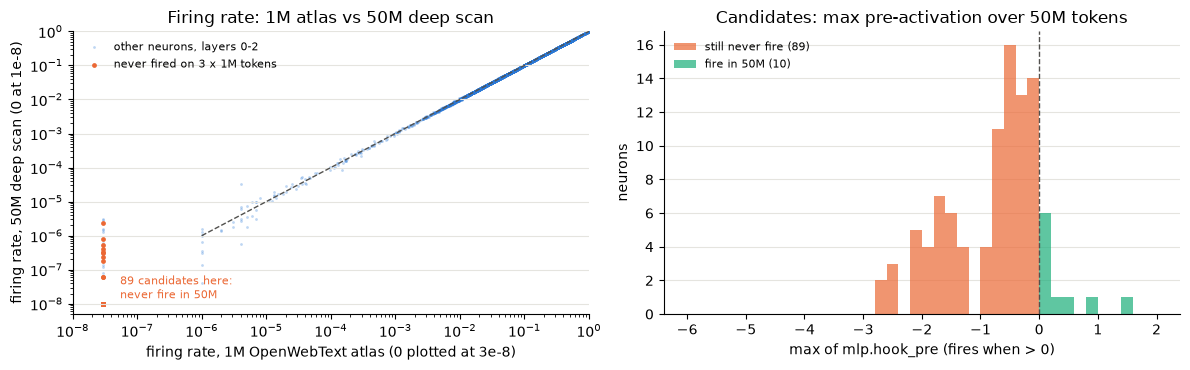

In [12]:
DEEP = Path("../results/deepscan-owt")
deep = duckdb.sql(f"select * from '{DEEP / 'neurons.parquet'}'").df().set_index(["layer", "unit"])
deep_topk = duckdb.sql(f"select * from '{DEEP / 'topk.parquet'}'").df()
dman = json.loads((DEEP / "manifest.json").read_text())
deep["fires"] = np.rint(deep.frac_pos * deep.n).astype(int)
print(f"deep scan: {deep.n.iloc[0]:,} tokens per unit from {dman['n_docs']:,} documents ({dman['dataset']} files {dman['files']})")

post = {name: c.neurons[c.neurons.kind == "post"].set_index(["layer", "unit"]) for name, c in corp.items()}
never_all = np.logical_and.reduce([p.frac_pos.to_numpy() == 0 for p in post.values()])
cand = post["OpenWebText"].index[never_all]
scanned = cand[cand.get_level_values("layer") <= 2]
dc = deep.loc[scanned]
print(f"never fired on 3 x 1M tokens: {len(cand)} neurons; {len(scanned)} in layers 0-2, scanned here")
print("\nlayer  candidates  fire in 50M  still never   (rate bound if never: < 3 / 50M = 6e-8, 95% CL)")
for l in range(3):
    x = dc.loc[l] if l in dc.index.get_level_values(0) else dc.iloc[:0]
    print(f"{l:5d}  {len(x):10d}  {(x.fires > 0).sum():11d}  {(x.fires == 0).sum():11d}")
woke = dc[dc.fires > 0]
print(f"\nthose that fire: {len(woke)}, firing on {woke.fires.min()}-{woke.fires.max()} of 50M tokens (median {woke.fires.median():.0f})")

# Rare neurons (rate < 1e-4 on OpenWebText, but > 0): how many firing examples the deep scan gives them.
owt_post = post["OpenWebText"].loc[deep.index]
rare = (owt_post.frac_pos > 0) & (owt_post.frac_pos < 1e-4)
print(f"rare in the 1M atlas ({rare.sum()} neurons in layers 0-2): median firing tokens {np.median(owt_post.frac_pos[rare] * owt_post.n[rare]):.0f} "
      f"in 1M, {deep.fires[rare].median():.0f} in the 50M deep scan")
# Sanity: where both are well measured, firing rates agree between the atlas and the deep scan.
ok = (owt_post.frac_pos > 1e-3).to_numpy()
r = (deep.frac_pos.to_numpy()[ok] / owt_post.frac_pos.to_numpy()[ok])
print(f"neurons firing on > 0.1% of tokens: deep / atlas firing-rate ratio, median {np.median(r):.3f}, 1st-99th pct {np.quantile(r, 0.01):.2f}-{np.quantile(r, 0.99):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
floor = 1e-8
x = np.maximum(owt_post.frac_pos.to_numpy(), floor * 3); y = np.maximum(deep.frac_pos.to_numpy(), floor)
is_c = deep.index.isin(scanned)
axes[0].scatter(x[~is_c], y[~is_c], s=4, color=C[0], alpha=0.3, lw=0, label="other neurons, layers 0-2")
axes[0].scatter(x[is_c], y[is_c], s=12, color=C[1], lw=0, label="never fired on 3 x 1M tokens")
axes[0].plot([1e-6, 1], [1e-6, 1], color=INK2, lw=1, ls="--")
axes[0].annotate(f"{(dc.fires == 0).sum()} candidates here:\nnever fire in 50M", (floor * 3, floor), xytext=(12, 4),
                 textcoords="offset points", fontsize=8, color=C[1])
axes[0].set(xscale="log", yscale="log", xlim=(1e-8, 1), ylim=(5e-9, 1), title="Firing rate: 1M atlas vs 50M deep scan",
            xlabel="firing rate, 1M OpenWebText atlas (0 plotted at 3e-8)", ylabel="firing rate, 50M deep scan (0 at 1e-8)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
for vals, color, label in [(dc.loc[dc.fires == 0, "max"], C[1], "still never fire"), (dc.loc[dc.fires > 0, "max"], C[2], "fire in 50M")]:
    if len(vals):
        axes[1].hist(vals, bins=np.linspace(-6, 2, 41), color=color, alpha=0.7, label=f"{label} ({len(vals)})", zorder=2)
axes[1].axvline(0, color=INK2, lw=1, ls="--")
axes[1].set(title="Candidates: max pre-activation over 50M tokens", xlabel="max of mlp.hook_pre (fires when > 0)", ylabel="neurons")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    tidy(ax)
plt.tight_layout()
save(fig, "results_deepscan")

**Closest approaches.** For the never-firing neurons whose maximum comes nearest to 0, and those that stay furthest
from it, the contexts with the highest pre-activation; and for a few candidates that do fire in 50M tokens, the
contexts where they fire.

In [13]:
def show_deep(layer, unit, n=4):
    t = deep_topk[(deep_topk.layer == layer) & (deep_topk.unit == unit)].sort_values("rank").head(n)
    r = deep.loc[(layer, unit)]
    print(f"L{layer}/{unit}: fires on {r.fires} of {r.n:,} tokens, max pre-activation {r['max']:.3f}, mean {r['mean']:.2f}, std {r['std']:.2f}")
    for v, ctx in zip(t.value, t.context):
        print(f"    {v:7.3f}  {ctx[-80:]!r}")

silent = dc[dc.fires == 0].sort_values("max")
print("== never fire, closest to firing ==")
for l, u in silent.index[::-1][:3]:
    show_deep(l, u)
print("\n== never fire, furthest from firing ==")
for l, u in silent.index[:3]:
    show_deep(l, u)
print("\n== candidates that fire in 50M tokens ==")
for l, u in woke.sort_values("fires", ascending=False).index[:3]:
    show_deep(l, u)

== never fire, closest to firing ==
L0/1382: fires on 0 of 49,610,264 tokens, max pre-activation -0.030, mean -1.90, std 0.34
     -0.030  've after wave of fat undulates over his body before the« ref» steps in and calls'
     -0.068  ', in which the first column had one to six dots den«oting» the row in the'
     -0.114  'y, though the side effects the subjects who had« ref»rained from caffeine intake'
     -0.130  'more frequently, the cell tries to pick up the pace and« ref»old the proteins in'
L2/2980: fires on 0 of 49,610,264 tokens, max pre-activation -0.040, mean -1.67, std 0.26
     -0.040  'ut if I\'m not mad, and [Charlotte\'s] not mad, and we\'re the key players."«⏎»⏎His'
     -0.062  'friends because I wanted to hang out with him a lot. It was just surreal."«⏎»⏎On'
     -0.134  'face really serves to spread out the water and the dye to a very big patch.”«⏎»⏎'
     -0.137  'ything he\'s got and then a little bit more, and that\'s like gold."«⏎»⏎ON JOHN MO'
L0/2771: fires on 

**Reading it.** Of the 99 candidates in layers 0–2, 89 never fire in 50M tokens: a firing rate below 6×10⁻⁸ (95% CL),
25 in layer 0, 54 in layer 1 and 10 in layer 2. The other 10 are rare rather than silent, firing 3–118 times. The
silent ones split by how far they stay from firing. 31 stay more than 1 unit below 0 over all 50M tokens (L1/242: mean
−9.6, max −2.6), which is as close to dead as a sample can show. 32 come within 0.5 of firing (L0/1382 reaches −0.03),
so for them "never" may only mean "rarer than 1 in 50M". Their closest approaches are specific (the first token of
"ref…" words for L0/1382, the newline closing a quoted paragraph for L2/2980), much like the contexts of live neurons.
The scan also gives the rare neurons enough examples to study (median firing tokens 7 → 526), and where both are well
measured its firing rates agree with the 1M atlas (median ratio 1.000). Silent on OpenWebText is not silent everywhere:
two more layer 1 neurons (1822 and 2400) never fire in the 50M OpenWebText tokens, with maxima just below 0 (−0.02
and −0.01), yet fired on 1M tokens of code (33 and 2 times).

## 7. Regression check: pointers reproduce

Activations are a pure function of (weights, tokens), so the atlas stores exemplars as `(row, pos)` pointers. Recompute
a random sample of top- and bottom-k entries and check that each stored value comes back.

In [14]:
model = HFGPT2("cpu")
sample = topk.sample(12, random_state=0)
worst = 0.0
for r in sample.itertuples():
    got = {}
    toks = torch.tensor(tokens[[r.row]].astype(np.int64))
    model.run(toks, {r.hook: lambda act: got.__setitem__("x", act[0, r.pos, r.unit].item())})
    worst = max(worst, abs(got["x"] - r.value) / max(abs(r.value), 1e-3))
    print(f"{r.hook:26s} unit {r.unit:4d} rank {r.rank:2d}: stored {r.value:9.4f}  recomputed {got['x']:9.4f}")
print(f"worst relative difference {worst:.1e}")
assert worst < 1e-3

/Users/ryan/Development/gpt2-atlas/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 14137.03it/s]

blocks.7.mlp.hook_post     unit 1034 rank 16: stored    1.9075  recomputed    1.9075
blocks.0.mlp.hook_post     unit 3000 rank 17: stored    2.4603  recomputed    2.4603
blocks.3.hook_resid_pre    unit  342 rank 13: stored    7.2777  recomputed    7.2777
blocks.11.mlp.hook_post    unit 1657 rank 12: stored    3.2182  recomputed    3.2182
blocks.11.hook_resid_post  unit  640 rank  6: stored   44.7261  recomputed   44.7262
blocks.3.mlp.hook_post     unit  350 rank  6: stored    1.7650  recomputed    1.7650


blocks.8.hook_resid_pre    unit  157 rank 11: stored  -12.2525  recomputed  -12.2525
blocks.6.hook_resid_pre    unit  517 rank 14: stored    8.4427  recomputed    8.4427
blocks.0.mlp.hook_post     unit  825 rank  3: stored    2.6021  recomputed    2.6021
blocks.1.mlp.hook_post     unit 2564 rank  2: stored    2.1407  recomputed    2.1407
blocks.7.mlp.hook_post     unit 3001 rank 16: stored    3.0582  recomputed    3.0582


blocks.11.mlp.hook_post    unit 2843 rank 10: stored    3.5921  recomputed    3.5921
worst relative difference 1.4e-06
